In [52]:
# Library imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pickle

In [53]:
# Sklearn imports
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_curve, auc

In [54]:
# Classification Models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

In [55]:
# Set plot style
sns.set_theme(style="whitegrid")

In [56]:
print("Loading and Preprocessing Data...")
df = pd.read_csv("student_dataset_10000_rows.csv")
df

Loading and Preprocessing Data...


,study_hours,attendance,sleep_hours,internet_usage,assignments_completed,previous_score,exam_score,placement_status
0,7,56,8,7,10,62,100.00,Placed
1,4,69,5,3,8,56,100.00,Placed
2,11,60,7,6,10,45,100.00,Placed
3,8,99,9,8,4,55,90.17,Placed
4,5,52,8,6,8,40,78.82,Placed
...,...,...,...,...,...,...,...,...
9995,2,58,9,7,8,88,69.31,Not Placed
9996,7,98,6,9,4,87,100.00,Placed
9997,10,44,8,5,10,37,95.94,Placed
9998,10,75,7,5,8,52,88.61,Placed


In [57]:
# EDA 1: Basic Info and Missing Values

print("--- Dataset Information ---")
df.info()

print("\n--- Missing Values Check ---")
print(df.isnull().sum())

--- Dataset Information ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   study_hours            10000 non-null  int64  
 1   attendance             10000 non-null  int64  
 2   sleep_hours            10000 non-null  int64  
 3   internet_usage         10000 non-null  int64  
 4   assignments_completed  10000 non-null  int64  
 5   previous_score         10000 non-null  int64  
 6   exam_score             10000 non-null  float64
 7   placement_status       10000 non-null  object 
dtypes: float64(1), int64(6), object(1)
memory usage: 625.1+ KB

--- Missing Values Check ---
study_hours              0
attendance               0
sleep_hours              0
internet_usage           0
assignments_completed    0
previous_score           0
exam_score               0
placement_status         0
dtype: int64


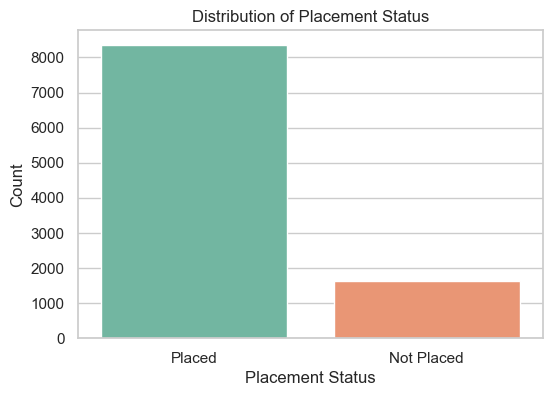

Class Counts:
placement_status
Placed        8356
Not Placed    1644
Name: count, dtype: int64

Class Percentages:
placement_status
Placed        83.56
Not Placed    16.44
Name: proportion, dtype: float64


In [58]:
# EDA 2: Placement Class Distribution

plt.figure(figsize=(6, 4))
# Note: Added hue and legend=False to prevent the seaborn deprecation warning seen in the main file
sns.countplot(data=df, x='placement_status', hue='placement_status', palette='Set2', legend=False)
plt.title('Distribution of Placement Status')
plt.xlabel('Placement Status')
plt.ylabel('Count')
plt.show()

print("Class Counts:")
print(df['placement_status'].value_counts())

print("\nClass Percentages:")
print(df['placement_status'].value_counts(normalize=True) * 100)

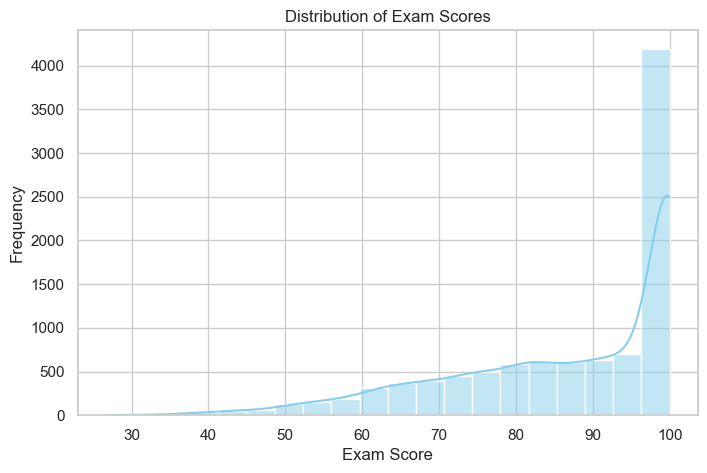

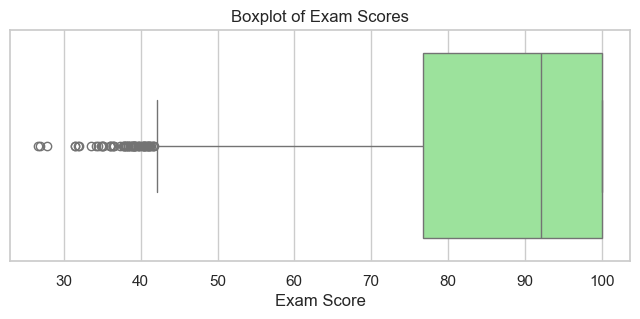

Exam Score Summary Statistics:
count    10000.000000
mean        86.704207
std         15.058383
min         26.670000
25%         76.727500
50%         92.120000
75%        100.000000
max        100.000000
Name: exam_score, dtype: float64


In [59]:
# EDA 3: Exam Score Distribution

# Histogram with KDE to visualize the distribution
plt.figure(figsize=(8, 5))
# Note: Adjust 'exam_score' if the column name differs in your dataset
sns.histplot(data=df, x='exam_score', kde=True, color='skyblue', bins=20)
plt.title('Distribution of Exam Scores')
plt.xlabel('Exam Score')
plt.ylabel('Frequency')
plt.show()

# Boxplot to identify potential outliers
plt.figure(figsize=(8, 3))
sns.boxplot(data=df, x='exam_score', color='lightgreen')
plt.title('Boxplot of Exam Scores')
plt.xlabel('Exam Score')
plt.show()

# Display statistical summary
print("Exam Score Summary Statistics:")
print(df['exam_score'].describe())

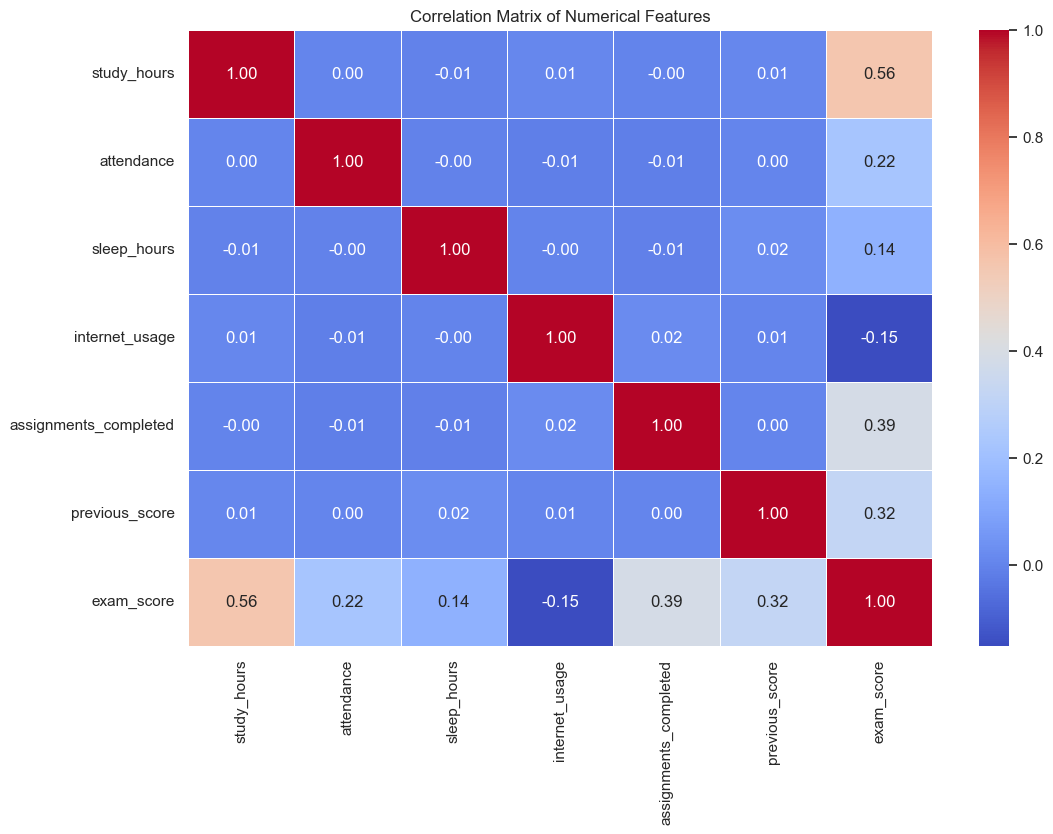

In [60]:
# EDA 4: Correlation Matrix

plt.figure(figsize=(12, 8))
# Select only numeric columns to avoid errors with categorical text columns
numeric_df = df.select_dtypes(include=[np.number])

sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Correlation Matrix of Numerical Features')
plt.show()

In [61]:
# Drop ID column safely if it exists
df = df.drop(columns=['student_id'], errors='ignore')

In [62]:
# One-hot encode categorical variables

# Convert categorical variables into dummy/indicator variables
# drop_first=True is used to avoid the dummy variable trap (multicollinearity)
df = pd.get_dummies(df, drop_first=True)

# Verify the changes
print(f"Dataset shape after encoding: {df.shape}")
display(df.head())

Dataset shape after encoding: (10000, 8)


,study_hours,attendance,sleep_hours,internet_usage,assignments_completed,previous_score,exam_score,placement_status_Placed
0,7,56,8,7,10,62,100.00,True
1,4,69,5,3,8,56,100.00,True
2,11,60,7,6,10,45,100.00,True
3,8,99,9,8,4,55,90.17,True
4,5,52,8,6,8,40,78.82,True


In [63]:
# Define features (X) and target variable (y)
# Updated to use the one-hot encoded column name
target_column = 'placement_status_Placed'

X = df.drop(columns=[target_column])
y = df[target_column]

print(f"Features (X) shape: {X.shape}")
print(f"Target (y) shape: {y.shape}")

Features (X) shape: (10000, 7)
Target (y) shape: (10000,)


In [64]:
# Split data into train and test sets

# Splitting the dataset into 80% training data and 20% testing data
# random_state ensures reproducibility
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Verify the shape of the resulting splits
print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"y_test shape: {y_test.shape}")

X_train shape: (8000, 7)
X_test shape: (2000, 7)
y_train shape: (8000,)
y_test shape: (2000,)


In [65]:

# Initialize the StandardScaler
scaler = StandardScaler()

# Fit the scaler on the training data and transform it
# It is important to ONLY fit on the training data to prevent data leakage
X_train_scaled = scaler.fit_transform(X_train)

# Transform the test data using the same scaler
X_test_scaled = scaler.transform(X_test)

# Verify the changes (showing the first row of scaled training data)
print("First row of scaled X_train:")
print(X_train_scaled[0])

First row of scaled X_train:
[ 1.57957213 -0.67513979 -0.88741767  0.29662844 -0.82248652  0.29736073
  0.50351501]


In [66]:
# 2. TRAIN MULTIPLE MODELS

print("\nTraining Models...")
models = {
    "Logistic Regression": LogisticRegression(random_state=42),
    "Decision Tree": DecisionTreeClassifier(max_depth=4, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Naive Bayes": GaussianNB(),
    "SVM": SVC(probability=True, random_state=42) 
}

results = {}
predictions = {}
predict_probas = {}

for name, model in models.items():
    # Train
    model.fit(X_train_scaled, y_train)
    
    # Predict
    y_pred = model.predict(X_test_scaled)
    predictions[name] = y_pred
    
    # Probabilities for ROC/AUC later on
    # Using [:, 1] to get the probability of the positive class
    y_prob = model.predict_proba(X_test_scaled)[:, 1]
    predict_probas[name] = y_prob
    
    # Accuracy
    acc = accuracy_score(y_test, y_pred)
    results[name] = acc
    
    print(f"\n--- {name} ---")
    print(classification_report(y_test, y_pred))


Training Models...

--- Logistic Regression ---
              precision    recall  f1-score   support

       False       0.99      0.99      0.99       345
        True       1.00      1.00      1.00      1655

    accuracy                           1.00      2000
   macro avg       1.00      1.00      1.00      2000
weighted avg       1.00      1.00      1.00      2000


--- Decision Tree ---
              precision    recall  f1-score   support

       False       1.00      1.00      1.00       345
        True       1.00      1.00      1.00      1655

    accuracy                           1.00      2000
   macro avg       1.00      1.00      1.00      2000
weighted avg       1.00      1.00      1.00      2000


--- Random Forest ---
              precision    recall  f1-score   support

       False       1.00      1.00      1.00       345
        True       1.00      1.00      1.00      1655

    accuracy                           1.00      2000
   macro avg       1.00      1.00

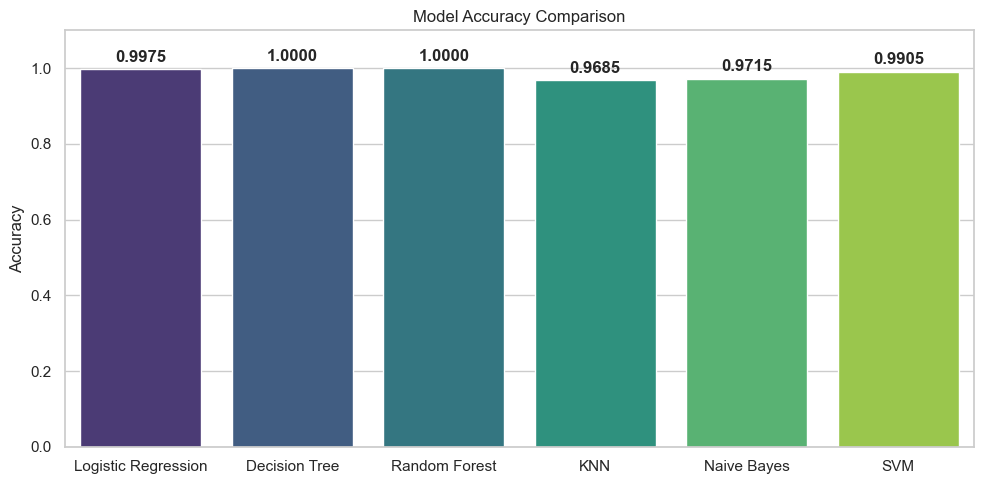

In [67]:
# 3. GRAPH: MODEL COMPARISON

plt.figure(figsize=(10, 5))

# Plotting the accuracies of the trained models
sns.barplot(
    x=list(results.keys()), 
    y=list(results.values()), 
    hue=list(results.keys()), 
    palette="viridis", 
    legend=False
)

plt.title("Model Accuracy Comparison")
plt.ylabel("Accuracy")
plt.ylim(0, 1.1) # Set upper limit to 1.1 to leave room for text labels

# Add the exact accuracy values on top of each bar
for i, v in enumerate(results.values()):
    plt.text(i, v + 0.02, f"{v:.4f}", ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

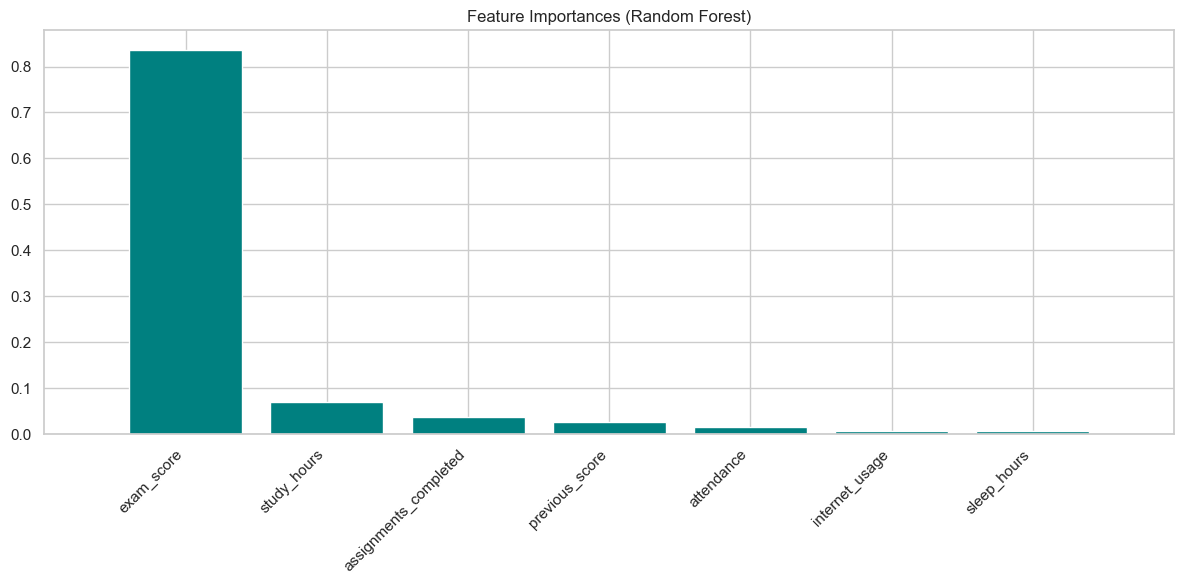

In [68]:
# 6. GRAPH: RANDOM FOREST FEATURE IMPORTANCE

# Assuming 'models' dictionary and 'X' dataframe are already defined
rf_model = models["Random Forest"]
importances = rf_model.feature_importances_
indices = np.argsort(importances)[::-1]
features = X.columns

plt.figure(figsize=(12, 6))
plt.title("Feature Importances (Random Forest)")
plt.bar(range(X.shape[1]), importances[indices], align="center", color='teal')
plt.xticks(range(X.shape[1]), [features[i] for i in indices], rotation=45, ha='right')
plt.xlim([-1, X.shape[1]])
plt.tight_layout()
plt.show()

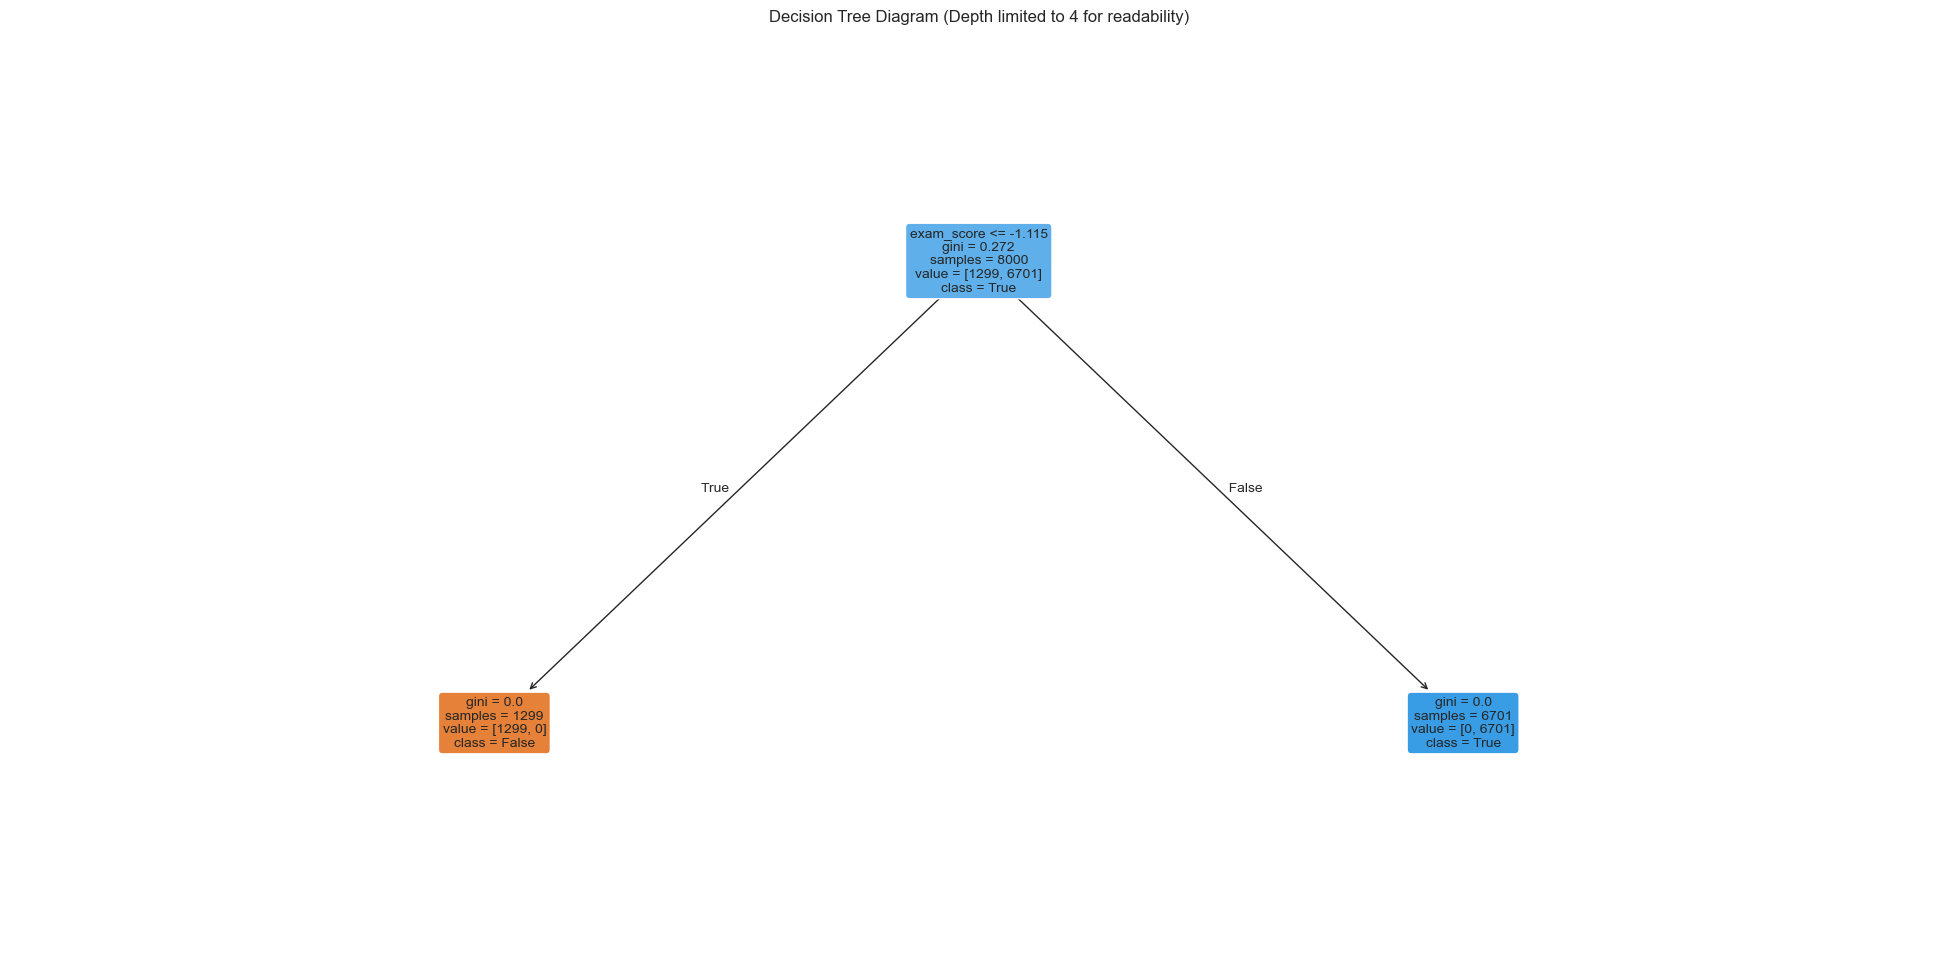

In [69]:
# 7. GRAPH: DECISION TREE DIAGRAM

# Extract the trained Decision Tree from the models dictionary
dt_model = models["Decision Tree"]

plt.figure(figsize=(25, 12))

# Dynamically extract class names from the model and convert them to strings
class_labels = [str(c) for c in dt_model.classes_]

plot_tree(dt_model, 
          feature_names=X.columns.tolist(), 
          class_names=class_labels, 
          filled=True, 
          rounded=True, 
          fontsize=10)

plt.title("Decision Tree Diagram (Depth limited to 4 for readability)")
plt.show()

In [70]:
# 8. SAVE BEST MODEL FOR STREAMLIT (Random Forest)
import pickle

print("\nSaving Random Forest model and artifacts for Streamlit...")

# Save the Random Forest model
with open('model.pkl', 'wb') as f:
    pickle.dump(rf_model, f)

# Save the scaler for preprocessing new data
with open('scaler.pkl', 'wb') as f:
    pickle.dump(scaler, f)

# Save the feature columns to ensure correct input shape
with open('columns.pkl', 'wb') as f:
    pickle.dump(X.columns.tolist(), f)

print("Saved successfully!")


Saving Random Forest model and artifacts for Streamlit...
Saved successfully!
